# Chapter 4 — Forward kinematics
**L4: transform chains, PoE, DH, URDF, and Pinocchio.**

**Run from top to bottom.** Install the repository's `requirements-kinematics.txt` in your notebook environment, then select **Run All Cells**. No robot assets need downloading. Angles are in radians, lengths in metres, and twists are ordered $(v,\omega)$. All computations run locally; no robot commands are issued.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pinocchio as pin
from scipy.linalg import expm

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': True,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Pinocchio', pin.__version__, '| NumPy', np.__version__)


Pinocchio 3.9.0 | NumPy 2.3.5


## 1. The same two-link arm as in the lecture
Both links are 1 m. $T_{sb}$ maps tool coordinates to world coordinates. At $q=(0,\pi/2)$ the tool is at $(1,1,0)$ and is turned $90^\circ$ about $z$.


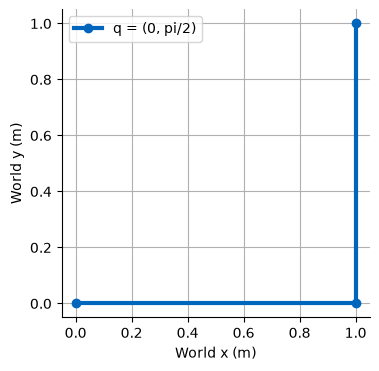

In [2]:
def position(q):
    q1, q2 = q
    return np.array([np.cos(q1) + np.cos(q1+q2),
                     np.sin(q1) + np.sin(q1+q2)])

def jacobian(q):
    q1, q2 = q
    return np.array([[-np.sin(q1)-np.sin(q1+q2), -np.sin(q1+q2)],
                     [ np.cos(q1)+np.cos(q1+q2),  np.cos(q1+q2)]])

def arm_points(q):
    elbow = np.array([np.cos(q[0]), np.sin(q[0])])
    return np.vstack(([0., 0.], elbow, position(q)))

def draw_arm(ax, q, label=None, **kwargs):
    xy = arm_points(q)
    ax.plot(xy[:, 0], xy[:, 1], 'o-', label=label, **kwargs)
    ax.set(xlabel='World x (m)', ylabel='World y (m)', aspect='equal')

q = np.array([0., np.pi/2])
np.testing.assert_allclose(position(q), [1, 1], atol=1e-12)
fig, ax = plt.subplots()
draw_arm(ax, q, label='q = (0, pi/2)', color='#0065BD', linewidth=3)
ax.legend(); plt.show()


## 2. Geometry, product of exponentials, and standard DH agree
The home pose is $T_0=\operatorname{Trans}_x(2)$. Translation-first space screws are $S_1=(0,0,0,0,0,1)$ and $S_2=(0,-1,0,0,0,1)$.
Use 4×4 matrices throughout the transform product. For this planar arm, standard DH has $d_i=\alpha_i=0$, $a_i=1$, and $\theta_i=q_i$.


In [3]:
def hat6(V):
    v, w = V[:3], V[3:]
    H = np.zeros((4, 4))
    H[:3, :3] = pin.skew(w)
    H[:3, 3] = v
    return H

def rotation_z(q):
    T = np.eye(4)
    T[:3, :3] = pin.exp3(np.array([0., 0., q]))
    return T

def translation_x(length):
    T = np.eye(4); T[0, 3] = length
    return T

def fk_chain(q):
    return rotation_z(q[0]) @ translation_x(1) @ rotation_z(q[1]) @ translation_x(1)

S1 = np.array([0., 0., 0., 0., 0., 1.])
S2 = np.array([0., -1., 0., 0., 0., 1.])
T0 = translation_x(2)

def fk_poe(q):
    return expm(hat6(S1)*q[0]) @ expm(hat6(S2)*q[1]) @ T0

def dh(theta, d, a, alpha):
    c, s, ca, sa = np.cos(theta), np.sin(theta), np.cos(alpha), np.sin(alpha)
    return np.array([[c, -s*ca, s*sa, a*c], [s, c*ca, -c*sa, a*s],
                     [0, sa, ca, d], [0, 0, 0, 1.]])

for angles in ([0., 0.], [0., np.pi/2], [.4, -.7], [-1., 1.2]):
    T = fk_chain(angles)
    np.testing.assert_allclose(T, fk_poe(angles), atol=1e-12)
    np.testing.assert_allclose(T, dh(angles[0],0,1,0) @ dh(angles[1],0,1,0), atol=1e-12)
    np.testing.assert_allclose(T[:2, 3], position(angles), atol=1e-12)
print('All three descriptions agree. T_sb at the lecture configuration:')
print(fk_chain(q))


All three descriptions agree. T_sb at the lecture configuration:
[[ 0. -1.  0.  1.]
 [ 1.  0.  0.  1.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]


## 3. Read a complete robot description
This implements the robot-description workflow in L4 slide 12 as a complete XML model. The elbow's fixed origin is 1 m along the upper arm's x-axis; its motion is about the joint z-axis. The **fixed tool joint** contributes the second 1 m offset.

The minimal model describes kinematics only: it has no calibrated inertias and is not a dynamics model. Joint limits are model data; a forward-kinematics call does not enforce them.


In [4]:
from IPython.display import Code, display
display(Code('<robot name="course_planar_2r">\n  <link name="base"/>\n  <link name="upper_arm"/>\n  <link name="forearm"/>\n  <link name="tool"/>\n  <joint name="shoulder" type="revolute">\n    <parent link="base"/><child link="upper_arm"/>\n    <origin xyz="0 0 0" rpy="0 0 0"/><axis xyz="0 0 1"/>\n    <limit lower="-3.14159265" upper="3.14159265" effort="20" velocity="2"/>\n  </joint>\n  <joint name="elbow" type="revolute">\n    <parent link="upper_arm"/><child link="forearm"/>\n    <origin xyz="1 0 0" rpy="0 0 0"/><axis xyz="0 0 1"/>\n    <limit lower="-2.8" upper="2.8" effort="20" velocity="2"/>\n  </joint>\n  <joint name="tool_mount" type="fixed">\n    <parent link="forearm"/><child link="tool"/>\n    <origin xyz="1 0 0" rpy="0 0 0"/>\n  </joint>\n</robot>', language='xml'))

<robot name="course_planar_2r">
  <link name="base"/>
  <link name="upper_arm"/>
  <link name="forearm"/>
  <link name="tool"/>
  <joint name="shoulder" type="revolute">
    <parent link="base"/><child link="upper_arm"/>
    <origin xyz="0 0 0" rpy="0 0 0"/><axis xyz="0 0 1"/>
    <limit lower="-3.14159265" upper="3.14159265" effort="20" velocity="2"/>
  </joint>
  <joint name="elbow" type="revolute">
    <parent link="upper_arm"/><child link="forearm"/>
    <origin xyz="1 0 0" rpy="0 0 0"/><axis xyz="0 0 1"/>
    <limit lower="-2.8" upper="2.8" effort="20" velocity="2"/>
  </joint>
  <joint name="tool_mount" type="fixed">
    <parent link="forearm"/><child link="tool"/>
    <origin xyz="1 0 0" rpy="0 0 0"/>
  </joint>
</robot>

## 4. Evaluate the tool pose with Pinocchio
This expands the Pinocchio workflow introduced on L4 slide 12. `Model` holds structure; `Data` is mutable working storage. Joint and frame IDs are different indices. Update frame placements after forward kinematics and copy results you need to retain.


In [5]:
URDF = '<robot name="course_planar_2r">\n  <link name="base"/>\n  <link name="upper_arm"/>\n  <link name="forearm"/>\n  <link name="tool"/>\n  <joint name="shoulder" type="revolute">\n    <parent link="base"/><child link="upper_arm"/>\n    <origin xyz="0 0 0" rpy="0 0 0"/><axis xyz="0 0 1"/>\n    <limit lower="-3.14159265" upper="3.14159265" effort="20" velocity="2"/>\n  </joint>\n  <joint name="elbow" type="revolute">\n    <parent link="upper_arm"/><child link="forearm"/>\n    <origin xyz="1 0 0" rpy="0 0 0"/><axis xyz="0 0 1"/>\n    <limit lower="-2.8" upper="2.8" effort="20" velocity="2"/>\n  </joint>\n  <joint name="tool_mount" type="fixed">\n    <parent link="forearm"/><child link="tool"/>\n    <origin xyz="1 0 0" rpy="0 0 0"/>\n  </joint>\n</robot>'
model = pin.buildModelFromXML(URDF)
data = model.createData()
assert model.existFrame('tool')
fid = model.getFrameId('tool')
assert (model.nq, model.nv) == (2, 2)

def tool_pose(q):
    pin.forwardKinematics(model, data, np.asarray(q, dtype=float))
    pin.updateFramePlacements(model, data)
    return data.oMf[fid].copy()  # Data is overwritten by the next algorithm call.

print('Joints:', list(model.names))
print('Tool frame id:', fid, '| nq =', model.nq, '| nv =', model.nv)

for angles in ([0., 0.], [0., np.pi/2], [.4, -.7], [-1., 1.2]):
    T = tool_pose(angles)
    np.testing.assert_allclose(T.homogeneous, fk_chain(angles), atol=1e-12)
print('Pinocchio agrees with the geometry, DH, and PoE.')
print(tool_pose(q).homogeneous)


Joints: ['universe', 'shoulder', 'elbow']
Tool frame id: 7 | nq = 2 | nv = 2
Pinocchio agrees with the geometry, DH, and PoE.
[[ 0. -1.  0.  1.]
 [ 1.  0.  0.  1.]
 [ 0.  0.  1.  0.]
 [ 0.  0.  0.  1.]]


## Try it
Change one joint at a time and inspect the tool pose. Then change the tool offset in the XML and explain why the old analytic checks should fail until the geometry is updated too.

Next: [Chapter 5 — Jacobians and accelerations](../05-velocity-kinematics/01_jacobians_and_accelerations.ipynb).

Reference: [Pinocchio model-loading documentation](https://gepettoweb.laas.fr/doc/stack-of-tasks/pinocchio/devel/doxygen-html/md_doc_2b-examples_2a-model.html). The robot model and worked code here are original course material.
